# Minimum weight perfect matching implementation

**Reference paper**: https://arxiv.org/pdf/2105.13082

### First implementation: k=1 repetition code

Num qubits `n=3`; check matrix `H=[[1, 1, 0]; [0, 1, 1]]` rank 2; `n - rank(H) = 1` data qubit

We use `stim` repetition code simulator with a `Matching` object we define from our known check matrix 

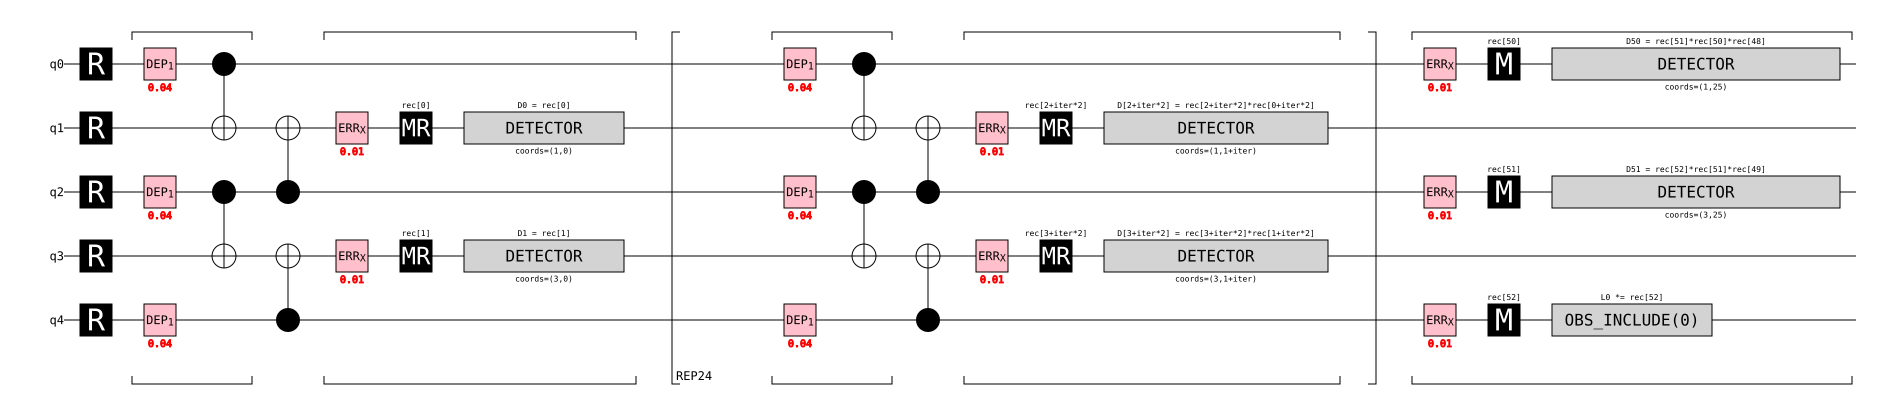

In [1]:
# construct stim simulator for data generation. repetition code circuit d=3
import stim
repetition_ckt = stim.Circuit.generated(
    "repetition_code:memory",
    rounds=25,
    distance=3,
    before_measure_flip_probability=0.01,
    before_round_data_depolarization=0.04
)
repetition_ckt.diagram('timeline-svg')

In [2]:
# show errors as 1 when simulating the circuit. tracks each channel
sampler = repetition_ckt.compile_sampler()
result = sampler.sample(shots=3)[0]
print("".join("1" if e else "_" for e in result))

_____________________________________________________


In [3]:
# now show errors tracking the detector
# results are much more sparse because we are tracking detected errors, not just whether error happens or not on channel
# foundation for error correction: flips come in pairs
detector_sampler = repetition_ckt.compile_detector_sampler()
result = detector_sampler.sample(shots=3)[0]
print("".join("1" if e else "_" for e in result))

____11________________________________________1_1___


## Matching decoder initialization

Now we initialize a detector error model (DEM) directly from the circuit data, and use it to construct a `pymatching.Matching` graph that encodes the syndrome data from the circuit as a MWPM graph

In [4]:
from pymatching import Matching

def mwpm_from_dem(meas_err_rate: float, data_err_rate: float, suppress_results: bool=False, distance: int=3, rounds: int=25):
    repetition_ckt = stim.Circuit.generated(
        "repetition_code:memory",
        rounds=rounds,
        distance=distance,
        before_measure_flip_probability=meas_err_rate,
        before_round_data_depolarization=data_err_rate,
    )
    dem = repetition_ckt.detector_error_model(decompose_errors=True)
    detector_sampler = repetition_ckt.compile_detector_sampler()
    # dynamically adjust detector shots based on error rate
    if meas_err_rate >= 1e-2:
        detector_shots = 10**3
    elif meas_err_rate < 1e-2 and meas_err_rate >= 1e-3:
        detector_shots = 10**4
    else:
        detector_shots = 10**5

    detection_events, observable_flips = detector_sampler.sample(shots=detector_shots, separate_observables=True)

    m = Matching.from_detector_error_model(dem)
    predictions = m.decode_batch(detection_events)

    prediction_errors = 0
    for i, flip in enumerate(observable_flips):
        if predictions[i] != flip:
            prediction_errors += 1

    prediction_error_rate = round(prediction_errors / len(predictions), 3)
    if not suppress_results:
        print(f"MWPM error rate: {prediction_error_rate}")
        print(f"Missed {prediction_errors} / {len(predictions)} detector errors.")

    return prediction_error_rate

error_rate = mwpm_from_dem(0.04, 0.01)

MWPM error rate: 0.017
Missed 17 / 1000 detector errors.


Text(0, 0.5, 'Average errors (actual pauli flips vs. predicted)')

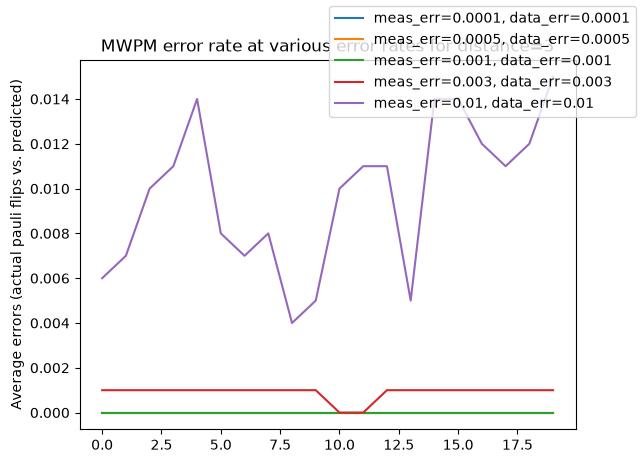

In [5]:
import matplotlib.pyplot as plt

def run_mwpm(meas_err_rate: float, data_err_rate: float, num_shots: int=20, distance: int=3):
    results = []
    for i in range(num_shots):
        prediction_error_rate = mwpm_from_dem(meas_err_rate, data_err_rate, distance=distance, suppress_results=True)
        results.append(prediction_error_rate)
    return results

# hardware-realistic error rates
error_rates = [
    (1e-4, 1e-4), 
    (5e-4, 5e-4), 
    (1e-3, 1e-3),
    (3e-3, 3e-3),
    (1e-2, 1e-2)
]
num_shots = 20
distance = 3
result = []
for pair in error_rates:
    meas_err, data_err = pair
    d_3_error_rate = run_mwpm(meas_err_rate=meas_err, data_err_rate=data_err, distance=distance, num_shots=num_shots)
    result.append((d_3_error_rate, meas_err, data_err))

fig, ax = plt.subplots()
for i, res in enumerate(result):
    meas_err = result[i][1]
    data_err = result[i][2]
    ax.plot(res[0], label=f"meas_err={meas_err}, data_err={data_err}")
fig.legend(loc='outside right upper')
plt.title(f"MWPM error rate at various error rates for distance={distance}")
plt.ylabel("Average errors (actual pauli flips vs. predicted)")

Text(0, 0.5, 'Average errors (actual pauli flips vs. predicted)')

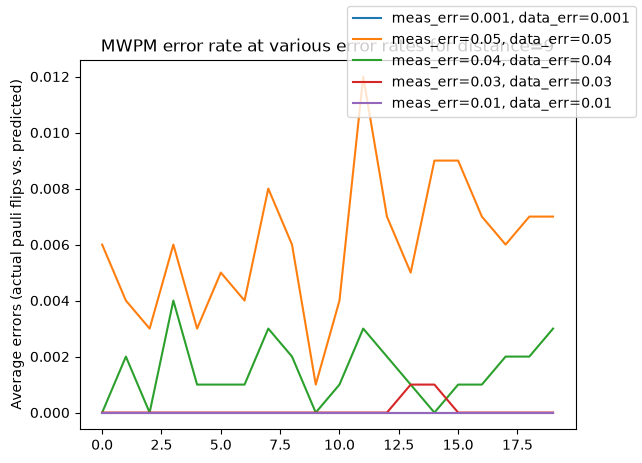

In [6]:
import numpy as np
# scale error rates up since distance is greater
error_rates = [
    (1e-3, 1e-3), 
    (5e-2, 5e-2), 
    (4e-2, 4e-2),
    (3e-2, 3e-2),
    (1e-2, 1e-2)
]
num_shots = 20
distance = 9
result = []
for pair in error_rates:
    meas_err, data_err = pair
    d_9_error_rate = run_mwpm(meas_err_rate=meas_err, data_err_rate=data_err, distance=distance, num_shots=num_shots)
    result.append((d_9_error_rate, meas_err, data_err))

fig, ax = plt.subplots()
for i, res in enumerate(result):
    meas_err = result[i][1]
    data_err = result[i][2]
    ax.plot(res[0], label=f"meas_err={meas_err}, data_err={data_err}")
fig.legend(loc='outside right upper')
plt.title(f"MWPM error rate at various error rates for distance={distance}")
plt.ylabel("Average errors (actual pauli flips vs. predicted)")
    

## Discussion of results so far

The near-perfect accuracy of MWPM on repetition code as demonstrated is an artifact of the type of errors that can possibly manifest on repetition code. Repetition code only protects against one Pauli type of error, depending on the parity-check ran from data to ancilla qubit. Here we track X-flips and MWPM is able to pick up on almost all of them because the DEM in repetition code is graphlike (TODO: need to prove this mathematically to improve quality of discussion), and MWPM is a graph algorithm. 

Practical limitations: 
- Real hardware has 3 types of Pauli flips (X, Z, Y) that repetition code can only see one of
- Since the repetition code DEM is graphlike, it cannot represent hyperedges (>2 correlated nodes for given error pattern); hyperedges are more common in surface code topologies so MWPM breaks down (TODO: run MWPM against surface code and demonstrate worse accuracy)

In [11]:
# demonstrate that MWPM gets cooked by surface code. first redefine functions
distance = 3
# add error rate for hook errors (after CNOT gate error, not included in repetition code). produces hyperedges
error_rates = [
    5e-3,
    4e-3,
    3e-3,
    2e-3,
    1e-3
]

def surface_mwpm_from_dem(p_err: float, suppress_results: bool=False, distance: int=3, rounds: int=5):
    repetition_ckt = stim.Circuit.generated(
        "surface_code:rotated_memory_z",
        rounds=rounds,
        distance=distance,
        before_measure_flip_probability=p_err,
        before_round_data_depolarization=p_err,
        after_clifford_depolarization=p_err
    )
    dem = repetition_ckt.detector_error_model(decompose_errors=True)
    detector_sampler = repetition_ckt.compile_detector_sampler()

    detector_shots = 2*10**5

    detection_events, observable_flips = detector_sampler.sample(shots=detector_shots, separate_observables=True)

    m = Matching.from_detector_error_model(dem)
    predictions = m.decode_batch(detection_events)

    prediction_errors = 0
    for i, flip in enumerate(observable_flips):
        if predictions[i] != flip:
            prediction_errors += 1

    prediction_error_rate = round(prediction_errors / len(predictions), 3)
    if not suppress_results:
        print(f"MWPM error rate: {prediction_error_rate}")
        print(f"Missed {prediction_errors} / {len(predictions)} detector errors.")

    return prediction_error_rate

def surface_run_mwpm(p_err: float, num_shots: int=20, distance: int=3):
    results = []
    for i in range(num_shots):
        prediction_error_rate = surface_mwpm_from_dem(p_err, distance=distance, suppress_results=True)
        results.append(prediction_error_rate)
    return results

Text(0, 0.5, 'Logical error rate per shot')

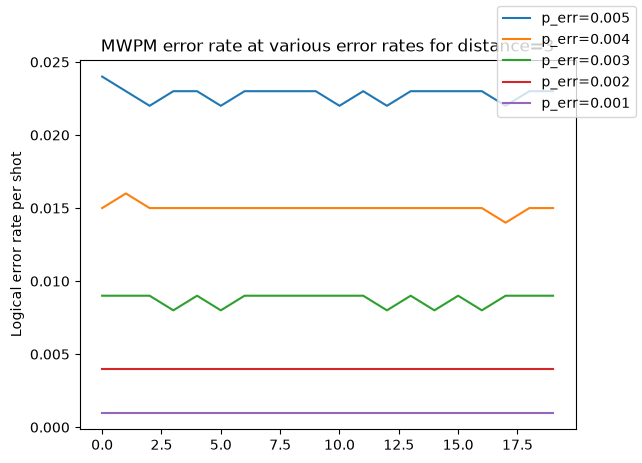

In [12]:
result = []
for p in error_rates:
    surface_error_rate = surface_run_mwpm(p_err=p, distance=distance)
    result.append((surface_error_rate, p))

fig, ax = plt.subplots()
for i, res in enumerate(result):
    p_err = res[1]
    ax.plot(res[0], label=f"p_err={p_err}")
fig.legend(loc='outside right upper')
plt.title(f"MWPM error rate at various error rates for distance={distance}")
plt.ylabel("Logical error rate per shot")

**Comments**: 
- with shots=1000 we don't get enough shots for errors to occur with p_err=0.001
- for increasing error past that we can see how cooked mwpm is for surface code. errors no longer coerced to be graphlike

In [9]:
c = stim.Circuit.generated("surface_code:rotated_memory_z", distance=3, rounds=3,
        before_measure_flip_probability=0.01, before_round_data_depolarization=0.01)
print(c)                              # read the DETECTOR lines
# print(c.detector_error_model())
# c.diagram('timeline-svg')

QUBIT_COORDS(1, 1) 1
QUBIT_COORDS(2, 0) 2
QUBIT_COORDS(3, 1) 3
QUBIT_COORDS(5, 1) 5
QUBIT_COORDS(1, 3) 8
QUBIT_COORDS(2, 2) 9
QUBIT_COORDS(3, 3) 10
QUBIT_COORDS(4, 2) 11
QUBIT_COORDS(5, 3) 12
QUBIT_COORDS(6, 2) 13
QUBIT_COORDS(0, 4) 14
QUBIT_COORDS(1, 5) 15
QUBIT_COORDS(2, 4) 16
QUBIT_COORDS(3, 5) 17
QUBIT_COORDS(4, 4) 18
QUBIT_COORDS(5, 5) 19
QUBIT_COORDS(4, 6) 25
R 1 3 5 8 10 12 15 17 19 2 9 11 13 14 16 18 25
TICK
DEPOLARIZE1(0.01) 1 3 5 8 10 12 15 17 19
H 2 11 16 25
TICK
CX 2 3 16 17 11 12 15 14 10 9 19 18
TICK
CX 2 1 16 15 11 10 8 14 3 9 12 18
TICK
CX 16 10 11 5 25 19 8 9 17 18 12 13
TICK
CX 16 8 11 3 25 17 1 9 10 18 5 13
TICK
H 2 11 16 25
TICK
X_ERROR(0.01) 2 9 11 13 14 16 18 25
MR 2 9 11 13 14 16 18 25
DETECTOR(0, 4, 0) rec[-4]
DETECTOR(2, 2, 0) rec[-7]
DETECTOR(4, 4, 0) rec[-2]
DETECTOR(6, 2, 0) rec[-5]
REPEAT 2 {
    TICK
    DEPOLARIZE1(0.01) 1 3 5 8 10 12 15 17 19
    H 2 11 16 25
    TICK
    CX 2 3 16 17 11 12 15 14 10 9 19 18
    TICK
    CX 2 1 16 15 11 10 8 14 3 9 12 18


In [10]:
hit = stim.DetectorErrorModel("error(1) D2 D5 D6 D9")
for x in c.explain_detector_error_model_errors(dem_filter=hit,
                                               reduce_to_one_representative_error=True):
    print(x)

ExplainedError {
    dem_error_terms: D2[coords 4,4,0] D5[coords 2,2,1] D6[coords 4,2,1] D9[coords 2,4,1]
    [no single circuit error had these exact symptoms]
}
